# Demo 1｜补贴策略 A/B 实验评估

决策问题：补贴能否带来值得付费的增量完单？估计量为用户级 ITT；假设用户间没有显著供给干扰。主指标为实验期人均完单，护栏为取消率和等待时长。

**数据声明**：以下均为固定随机种子生成的模拟数据，不代表真实滴滴业务效果。图中的英文标签用于避免本地中文字体依赖。

## 设计与模拟数据

实验前固定 1:1 用户随机分流、双侧 α=0.05、功效 80%。样本量是量级估计，实际需用历史方差和聚类结构校准。数据字典：`arm` 分配；`pre_orders` 实验前订单；`orders` 实验期完单；`cancel` 取消率；`wait` 平均等待分钟；`spend` 补贴元。

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style='whitegrid')
rng = np.random.default_rng(20261028)
from statsmodels.stats.power import TTestIndPower
n=6000
pre=rng.poisson(2.0,n)
arm=rng.binomial(1,.5,n)
segment=rng.binomial(1,.35,n)
lam=np.maximum(.1,1.7+.34*pre+.18*segment+.18*arm+.12*arm*segment)
df=pd.DataFrame({'user_id':np.arange(n),'arm':arm,'segment':segment,'pre_orders':pre,'orders':rng.poisson(lam),'cancel':rng.binomial(1,np.clip(.11-.006*arm+.004*segment,.01,.9)),'wait':rng.normal(8-.05*arm,1.7,n),'spend':arm*rng.uniform(1.5,2.5,n)})
print(df.head())
print('Approx. users per arm for MDE 0.20:',round(TTestIndPower().solve_power(effect_size=.20/df.orders.std(),alpha=.05,power=.8)))

   user_id  arm  segment  pre_orders  orders  cancel      wait     spend
0        0    1        0           0       1       0  6.808806  1.507927
1        1    1        1           1       1       0  7.386901  1.639038
2        2    1        1           0       4       0  8.087061  2.423613
3        3    0        0           1       7       0  4.509383  0.000000
4        4    0        0           2       1       0  6.704467  0.000000
Approx. users per arm for MDE 0.20: 1126


## 分流与基线质量检查

先检查 SRM 和干预前行为平衡。SRM p 值低只提示分流或日志异常，不能证明具体故障。

Group sizes: {0: 2891, 1: 3109} SRM p= 0.0049 Baseline p= 0.8724


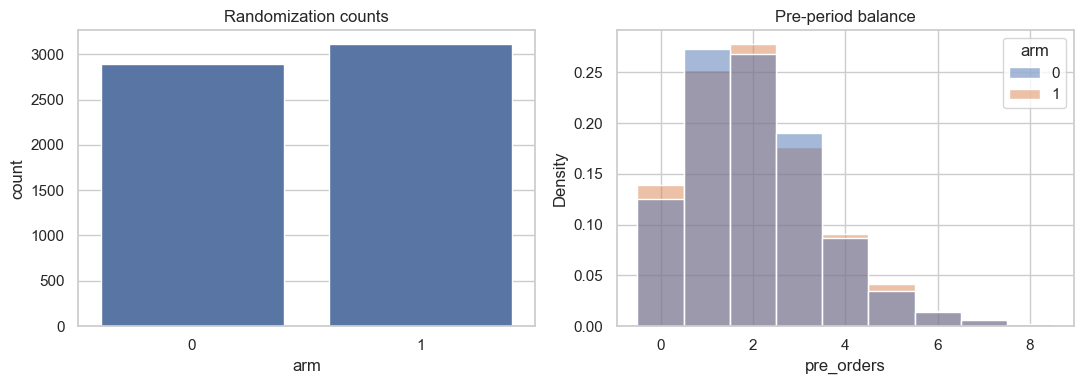

In [2]:
count=df.arm.value_counts().sort_index()
srm=stats.chisquare(count, f_exp=[n/2,n/2])
bal=stats.ttest_ind(df.loc[df.arm==1,'pre_orders'],df.loc[df.arm==0,'pre_orders'],equal_var=False)
print('Group sizes:',count.to_dict(),'SRM p=',round(srm.pvalue,4),'Baseline p=',round(bal.pvalue,4))
fig,ax=plt.subplots(1,2,figsize=(11,4))
sns.countplot(data=df,x='arm',ax=ax[0]);ax[0].set_title('Randomization counts')
sns.histplot(data=df,x='pre_orders',hue='arm',stat='density',common_norm=False,discrete=True,ax=ax[1]);ax[1].set_title('Pre-period balance')
plt.tight_layout();plt.show()

## ITT、CUPED 与业务成本

按原始分配估计 ITT。CUPED 仅使用干预前变量；系数由全样本协方差估计。比较原始与调整后区间，检查方差是否下降。每增量完单成本用补贴总额除以估计增量订单数；当增量接近零时该比值不稳定。

ITT: (np.float64(0.2734750174090932), np.float64(0.043535626983576034), (np.float64(0.18814518852128415), np.float64(0.35880484629690224))) CUPED: (np.float64(0.27151772657586637), np.float64(0.04180624055813322), (np.float64(0.18957749508192526), np.float64(0.3534579580698075))) Variance reduction: 0.07765797996394086
Subsidy per incremental order: 7.30127270132391


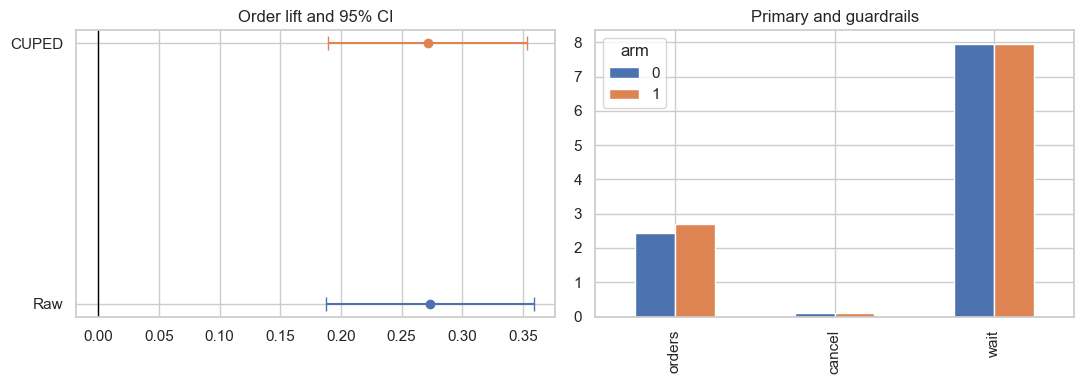

In [3]:
def diff_ci(y,a):
    x1=np.asarray(y)[a==1];x0=np.asarray(y)[a==0]
    d=x1.mean()-x0.mean();se=np.sqrt(x1.var(ddof=1)/len(x1)+x0.var(ddof=1)/len(x0))
    return d,se,(d-1.96*se,d+1.96*se)
a=df.arm.to_numpy();raw=diff_ci(df.orders.to_numpy(),a)
theta=np.cov(df.orders,df.pre_orders,ddof=1)[0,1]/df.pre_orders.var(ddof=1)
adj=df.orders-theta*(df.pre_orders-df.pre_orders.mean())
cuped=diff_ci(adj.to_numpy(),a)
print('ITT:',raw,'CUPED:',cuped,'Variance reduction:',1-adj.var()/df.orders.var())
print('Subsidy per incremental order:',df.spend.sum()/(raw[0]*(a==1).sum()))
fig,ax=plt.subplots(1,2,figsize=(11,4))
for i,(label,res) in enumerate([('Raw',raw),('CUPED',cuped)]):ax[0].errorbar(res[0],i,xerr=1.96*res[1],fmt='o',capsize=5,label=label)
ax[0].axvline(0,color='black',lw=1);ax[0].set_yticks([0,1],['Raw','CUPED']);ax[0].set_title('Order lift and 95% CI')
df.groupby('arm')[['orders','cancel','wait']].mean().T.plot(kind='bar',ax=ax[1]);ax[1].set_title('Primary and guardrails');plt.tight_layout();plt.show()

## 预设分层与决策摘要

模拟分层仅展示方法，子组结论应看交互项并控制多重检验。上线须同时满足收益大于补贴成本、护栏可接受及无严重干扰。

   segment      lift       low      high
0        0  0.247242  0.143291  0.351194
1        1  0.328970  0.180498  0.477442


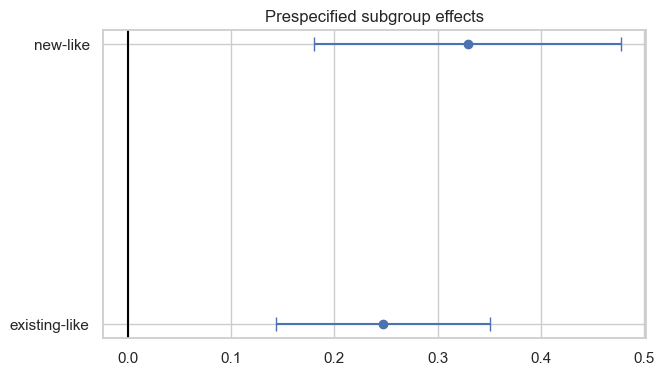

Decision: use estimated lift, cost and guardrails jointly; simulation cannot support a real launch.


In [4]:
rows=[]
for s,g in df.groupby('segment'):
    d,se,ci=diff_ci(g.orders.to_numpy(),g.arm.to_numpy());rows.append((s,d,*ci))
sub=pd.DataFrame(rows,columns=['segment','lift','low','high']);print(sub)
plt.figure(figsize=(7,4));plt.errorbar(sub.lift,sub.segment,xerr=[sub.lift-sub.low,sub.high-sub.lift],fmt='o',capsize=5);plt.axvline(0,color='black');plt.yticks([0,1],['existing-like','new-like']);plt.title('Prespecified subgroup effects');plt.show()
print('Decision: use estimated lift, cost and guardrails jointly; simulation cannot support a real launch.')

## 模拟结果解读与决策摘要

- 两组分别约 2891 与 3109 人，SRM 检验 p≈0.0049。若事先采用严格阈值 0.001，该项尚未触发阻断，但分流偏离仍值得排查；基线订单 p≈0.87，未见明显差异。
- 人均完单 ITT 约 **+0.273**，95% 区间约 **[+0.188,+0.359]**；CUPED 后约 **+0.272**，区间略窄，说明实验前行为提供了有限降方差收益。
- 模拟的每增量完单补贴成本约 **7.30 元**。是否推广仍取决于真实边际利润、留存价值和护栏表现；该成本比值未计其他运营成本。
- 分层效果是探索性信号；两个分层的置信区间重叠，不应仅据此宣称差异。司机共享供给可能使用户级随机实验低估或高估全量推广效果。


## 实证分析接入

当前目录没有可用于此案例的真实数据，故不把模拟结论解释为实际业务结论。接入真实数据时：①取得脱敏且获授权的数据；②核对数据字典、随机化/触达机制和时间窗；③用真实数据替换模拟数据生成单元；④重跑质量诊断与敏感性分析；⑤在审阅关键识别假设后更新决策摘要。